## Name: Sondos Mohamed Mohamed Abd Elmoniem Gafar

## ID: 2022/02126



## Final IMDb Movie Review Sentiment Analysis 

This notebook builds a **clean, end-to-end sentiment classifier** for the IMDb 50K movie reviews dataset.

It merges:
- **(preprocessing foundation)**: HTML removal, regex cleaning, stopword removal.
- **(modeling/evaluation)**: keeping negation words (e.g., **not/no**), feature extraction with BoW/TF‑IDF, and comparing multiple classifiers.
- **Summary**: tokenization, normalization, stopwords, stemming vs lemmatization, Bag-of-Words, TF‑IDF, n-grams, and standard ML evaluation.

### What is done in this notebook
- A comparison table for multiple **preprocessing × feature extraction × model** combinations
- Visualizations (class balance, length distribution, top words, confusion matrix, model comparison)
- A final conclusion summarizing the **best pipeline** and why it worked best


### 0) Setup: imports and reproducibility

We import the libraries we need for data handling, text processing, modeling, and evaluation.

**prepare data → normalize text → extract features → train → evaluate**.


In [1]:
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import FunctionTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

print("Ready")

Ready


RANDOM_STATE ensures reproducible random behavior in experiments.
np.random.seed() fixes randomness for consistent results.
plt.style.use() and sns.set_theme() improve graph appearance and readability.

### 1) Data understanding: load the IMDb dataset

Before any preprocessing, we must inspect the dataset itself.

Expected result: we load `IMDB Dataset.csv`, confirm the columns, preview rows, and confirm the dataset size matches expectations (50,000 rows).

In [2]:
DATA_PATH = "data/IMDB Dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head(5))

Shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


### 1.1) Missing values and duplicates

Checking missing values and duplicates is part of basic dataset quality control.

Result: 418 rows were duplicates so they were dropped, leaving 49582 rows.

In [3]:
missing = df.isna().sum()
dup_count = df.duplicated().sum()

print("Missing values per column:\n", missing)
print("Duplicate rows:", int(dup_count))

if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("After dropping duplicates, new shape:", df.shape)

Missing values per column:
 review       0
sentiment    0
dtype: int64
Duplicate rows: 418


After dropping duplicates, new shape: (49582, 2)


### 1.2) Sentiment distribution (class balance)

Class distribution matters because it affects evaluation: in imbalanced datasets, accuracy can be misleading.

Result: a roughly balanced split between `positive` and `negative`

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

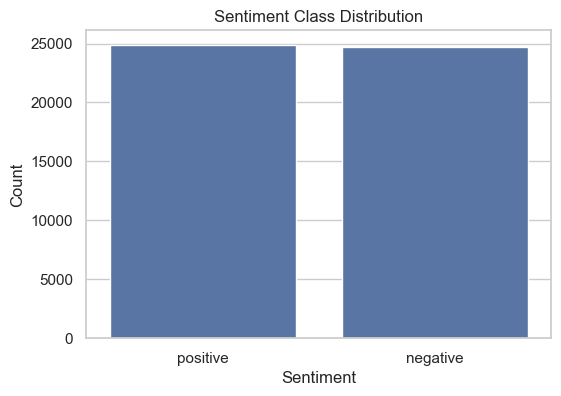

In [4]:
sent_counts = df["sentiment"].value_counts()
display(sent_counts)

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="sentiment", order=sent_counts.index)
ax.set_title("Sentiment Class Distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Count")
plt.show()

### 1.3) Review length distribution

Length distribution gives insight into whether we should do aggressive cleaning (e.g., remove HTML) and whether we should consider n-grams.

This cell is doing EDA (Exploratory Data Analysis) on the review lengths.

It checks:

how long reviews are in characters
how long reviews are in words
then visualizes the distribution

This cell performs exploratory data analysis on review lengths. It calculates character and word counts for each review, generates descriptive statistics with percentiles, and visualizes the word-length distribution using a histogram to understand dataset characteristics and outliers.

,review_char_len,review_word_len
count,49582.000000,49582.000000
mean,1310.568230,231.350167
std,990.762238,171.542020
min,32.000000,4.000000
50%,971.000000,173.000000
90%,2583.000000,452.000000
95%,3394.000000,591.000000
99%,5181.000000,908.000000
max,13704.000000,2470.000000


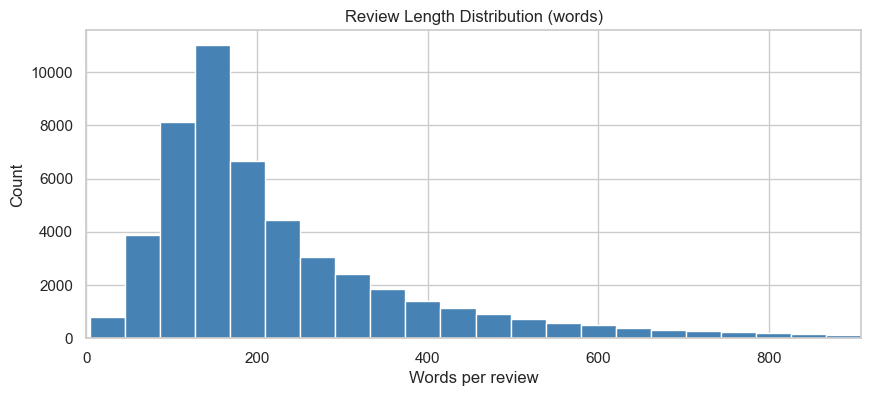

In [5]:
df["review_char_len"] = df["review"].astype(str).str.len()
df["review_word_len"] = df["review"].astype(str).str.split().str.len()

display(df[["review_char_len", "review_word_len"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

plt.figure(figsize=(10, 4))
plt.hist(df["review_word_len"], bins=60, color="steelblue")
plt.title("Review Length Distribution (words)")
plt.xlabel("Words per review")
plt.ylabel("Count")
plt.xlim(0, np.percentile(df["review_word_len"], 99))
plt.show()

The dataset contains approximately 50k reviews with an average length of 231 words. The distribution is positively skewed, meaning most reviews are short-to-medium length while a small number are extremely long outliers. The histogram confirms this long-tail behavior. Percentile analysis shows that 95% of reviews are under 591 words, which is useful for choosing sequence lengths and preprocessing strategies in NLP models.

### 1.4) What noise exists in the raw text?

We emphasize using **regular expressions** and **tokenization** to understand what kinds of characters/patterns exist (Lab 2 / Lecture 2).

Here we measure how often we see:
- HTML tags (e.g., `<br />`)
- URLs
- ALL CAPS words
- numbers
- punctuation / special characters

Expected result: HTML tags are common, and we may find punctuation/special characters that should be normalized.

In [ ]:
sample = df["review"].sample(2000, random_state=RANDOM_STATE).astype(str)

html_tag_rate = sample.str.contains(r"<[^>]+>", regex=True).mean()
url_rate = sample.str.contains(r"https?://|www\.", regex=True).mean()
has_number_rate = sample.str.contains(r"\d", regex=True).mean()

#regex: uppercase letters, at least 3 characters long
caps_rate = sample.str.contains(r"\b[A-Z]{3,}\b", regex=True).mean()

# punctuation/special chars: anything that's not a letter/number/space, example: !, #, etc..
special_rate = sample.str.contains(r"[^a-zA-Z0-9\s]", regex=True).mean()

noise_df = pd.DataFrame(
    {
        "pattern": ["HTML tags", "URLs", "Numbers", "ALL CAPS tokens", "Special chars/punct"],
        "fraction_of_sample": [html_tag_rate, url_rate, has_number_rate, caps_rate, special_rate],
    }
)
display(noise_df)

display(df.loc[df["review"].astype(str).str.contains(r"<br\s*/?>", regex=True), "review"].head(2))

,pattern,fraction_of_sample
0,HTML tags,0.5915
1,URLs,0.0035
2,Numbers,0.5650
3,ALL CAPS tokens,0.3930
4,Special chars/punct,1.0000


0    One of the other reviewers has mentioned that ...
1    A wonderful little production. <br /><br />The...
Name: review, dtype: str

The dataset contains substantial textual noise, especially HTML tags and punctuation. HTML artifacts appear in nearly 60% of sampled reviews, justifying HTML-cleaning preprocessing. Numbers and uppercase tokens are also common and may carry sentiment information (example 1/10 or 10/10, AMAZING or HORRIBLE. These carry emotional intensity), while URLs are very rare and likely insignificant for classification performance.



### Decision: preprocessing needed (based on the dataset)

From the inspection above we can justify these preprocessing steps:
- **Remove HTML tags** 
- **Remove URLs** 
- **Lowercasing** (normalization)
- **Regex cleaning** to remove non-letter characters
- **Tokenization** 
- **Stopword removal** but **keep negations**
- Compare **no stemming/lemmatization vs stemming vs lemmatization**
- **expand contractions** like can't to cannot.

Next, we implement a preprocessing function that can produce three variants: `none`, `stem`, and `lemma`.

### 2) Preprocessing utilities (NLTK-based)

We implement preprocessing using concepts from CSC441:
- **Regex + tokenization** (Word tokenization is used here)

Tokenization is the process of splitting text into smaller units called tokens, usually words. It is an essential NLP preprocessing step because machine learning models work on tokens rather than raw text.

- **Stopwords**: common words like the, is, am, are, of, in, etc..
- **Stemming vs Lemmatization** 

Stemming cuts words roughly (for example: beautiful → beauti). It can produce non-real words.

Lemmatization: More intelligent. It returns real dictionary word (for example better → good)

**we are not going to remove negation words** because they are very important for sentiment.
STOPWORDS = STOPWORDS - NEGATIONS_TO_KEEP

This cell defines the main text preprocessing pipeline. It removes HTML, expands contractions, removes URLs, accents, punctuation, numbers, extra spaces, tokenizes the text, removes stopwords while keeping negation words, and optionally applies stemming or lemmatization. This prepares the reviews for feature extraction and classification.

In [ ]:
import nltk

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

from bs4 import BeautifulSoup
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer

STOPWORDS = set(stopwords.words("english"))

# Keep negation words (Project2 idea + sentiment intuition)
NEGATIONS_TO_KEEP = {"no", "not", "never", "nor"}
STOPWORDS = STOPWORDS - NEGATIONS_TO_KEEP

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

CONTRACTIONS = {
    "can't": "can not",
    "won't": "will not",
    "n't": " not",
    "i'm": "i am",
    "it's": "it is",
    "that's": "that is",
    "there's": "there is",
    "what's": "what is",
    "don't": "do not",
    "didn't": "did not",
    "doesn't": "does not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "couldn't": "could not",
    "shouldn't": "should not",
    "wouldn't": "would not",
}

def expand_contractions(text: str) -> str:
    t = text
    t_lower = t.lower()
    # Replace longer/more specific keys first
    for k in sorted(CONTRACTIONS.keys(), key=len, reverse=True):
        t_lower = t_lower.replace(k, CONTRACTIONS[k])
    return t_lower

def strip_html(text: str) -> str:
    # Remove HTML tags
    return BeautifulSoup(text, "html.parser").get_text(" ")

#Removes accented characters (café → cafe).
def remove_accented(text: str) -> str:
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("utf-8", "ignore")

URL_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE) #remove URLs
#Although numbers can carry sentiment information such as ratings like “10/10”, they were removed here to simplify the vocabulary and reduce noise.
# In classical TF-IDF and Bag-of-Words pipelines, removing numbers is a common preprocessing choice because most numeric tokens contribute little to classification performance 
#compared to sentiment-bearing words.
NON_LETTER_RE = re.compile(r"[^a-zA-Z\s]") 
MULTISPACE_RE = re.compile(r"\s+") #remove space

def get_wordnet_pos(treebank_tag: str):
    #improve lemmatization using POS tags.
    #It tells WordNet whether a word is adj, verb, noun or adv.
    if treebank_tag.startswith("J"):
        return wordnet.ADJ
    if treebank_tag.startswith("V"):
        return wordnet.VERB
    if treebank_tag.startswith("N"):
        return wordnet.NOUN
    if treebank_tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

#This puts all the preprocessing steps before into a function
def preprocess_text(text: str, variant: str = "none", do_contractions: bool = True) -> str:
    """Return a cleaned string for vectorizers.

    variant:
      - 'none': normalization + stopwords
      - 'stem': apply Porter stemming
      - 'lemma': apply WordNet lemmatization (with POS)
    """
    t = str(text)
    t = strip_html(t)
    if do_contractions:
        t = expand_contractions(t)
    else:
        t = t.lower()
    t = URL_RE.sub(" ", t)
    t = remove_accented(t)
    t = NON_LETTER_RE.sub(" ", t)
    t = MULTISPACE_RE.sub(" ", t).strip()

    tokens = nltk.word_tokenize(t) #word tokenization
    tokens = [tok for tok in tokens if tok]  # safety (remove empty tokens)
    tokens = [tok for tok in tokens if tok not in STOPWORDS] #keep token only if it is not empty and stopword removal

    if variant == "stem":
        tokens = [stemmer.stem(tok) for tok in tokens]
    elif variant == "lemma":
        pos_tags = nltk.pos_tag(tokens) #Assigns grammatical type to each word. (helps lemma to preserve the meaning of the word)
        tokens = [lemmatizer.lemmatize(tok, get_wordnet_pos(tag)) for tok, tag in pos_tags] 
    elif variant != "none":
        raise ValueError("variant must be one of: 'none', 'stem', 'lemma'") #This prevents invalid input (for example:abc)

    return " ".join(tokens)

demo_text = df["review"].iloc[0]
print("Raw snippet:\n", str(demo_text)[:200], "...\n")
print("Preprocessed (none) snippet:\n", preprocess_text(demo_text, "none")[:200], "...\n")
print("Preprocessed (stem) snippet:\n", preprocess_text(demo_text, "stem")[:200], "...\n")
print("Preprocessed (lemma) snippet:\n", preprocess_text(demo_text, "lemma")[:200], "...")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sondo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sondo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\sondo\AppData\Roaming\nltk_data...


[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sondo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\sondo\AppData\Roaming\nltk_data...


[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\sondo\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\sondo\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


Raw snippet:
 One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me abo ...

Preprocessed (none) snippet:
 one reviewers mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scenes violence set right word go trust not show faint hearted timid show pulls no ...

Preprocessed (stem) snippet:
 one review mention watch oz episod hook right exactli happen first thing struck oz brutal unflinch scene violenc set right word go trust not show faint heart timid show pull no punch regard drug sex v ...



Preprocessed (lemma) snippet:
 one reviewer mention watch oz episode hook right exactly happen first thing strike oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regar ...


### 2.1) Visual check: frequent words before vs after preprocessing

We use frequency distributions to understand vocabulary.

We compute the most frequent tokens:
- Before preprocessing: raw text has HTML and punctuation noise.
- After preprocessing: we expect cleaner, sentiment-relevant terms.

Result: top words after preprocessing look more meaningful and less noisy.

,token,count,stage
0,the,27572,raw
1,and,13493,raw
2,a,13396,raw
3,of,11865,raw
4,to,11128,raw
5,is,8736,raw
6,br,8354,raw
7,in,7707,raw
8,it,7687,raw
9,i,7158,raw


,token,count,stage
0,not,5289,preprocessed_lemma
1,movie,4149,preprocessed_lemma
2,film,3980,preprocessed_lemma
3,one,2286,preprocessed_lemma
4,make,1803,preprocessed_lemma
5,like,1791,preprocessed_lemma
6,see,1697,preprocessed_lemma
7,get,1500,preprocessed_lemma
8,good,1356,preprocessed_lemma
9,time,1296,preprocessed_lemma


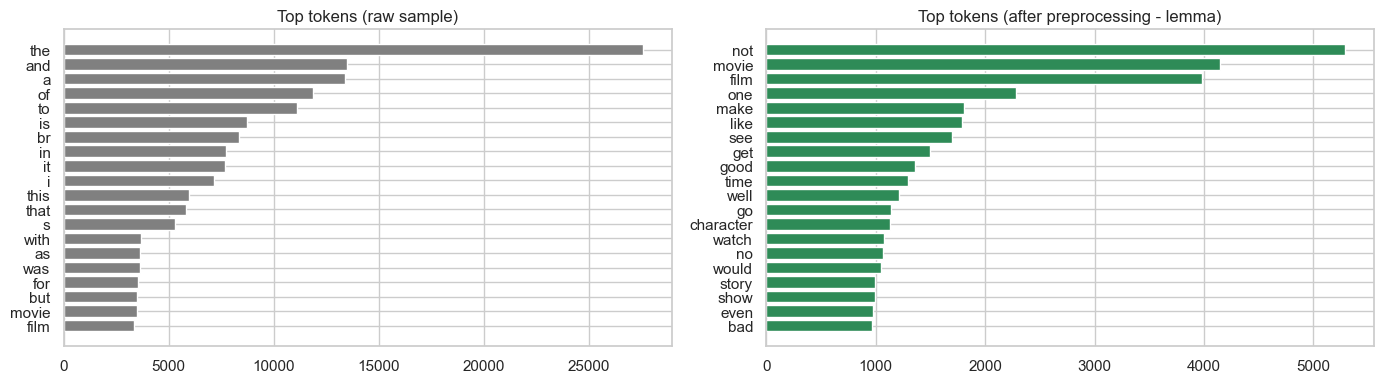

In [ ]:
def top_tokens_from_texts(texts, k=20): #it returns the 20 most common words.
    all_tokens = [] #Creates empty list to store all words.
    for t in texts: #Loops over every review.
        tokens = re.findall(r"\b[a-zA-Z]+\b", str(t).lower()) #Extracts only alphabetic words and lowercases them (Extract word tokens)
        all_tokens.extend(tokens) #Adds the tokens to the big list.
    return Counter(all_tokens).most_common(k) #Counts all words and returns the top 20.

#This checks top words before cleaning.
raw_top = top_tokens_from_texts(df["review"].sample(2000, random_state=RANDOM_STATE), k=20)

#This first cleans reviews using lemmatization, then counts top words.
clean_sample = df["review"].sample(2000, random_state=RANDOM_STATE).map(lambda x: preprocess_text(x, "lemma"))
clean_top = top_tokens_from_texts(clean_sample, k=20)

display(pd.DataFrame(raw_top, columns=["token", "count"]).assign(stage="raw"))
display(pd.DataFrame(clean_top, columns=["token", "count"]).assign(stage="preprocessed_lemma"))

#Creates 2 charts side by side.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

raw_df = pd.DataFrame(raw_top, columns=["token", "count"]).sort_values("count")
axes[0].barh(raw_df["token"], raw_df["count"], color="gray")
axes[0].set_title("Top tokens (raw sample)")

clean_df = pd.DataFrame(clean_top, columns=["token", "count"]).sort_values("count")
axes[1].barh(clean_df["token"], clean_df["count"], color="seagreen")
axes[1].set_title("Top tokens (after preprocessing - lemma)")

plt.tight_layout()
plt.show()

### 3) Train/test split and label encoding

**Label Encoding**: Machine learning models cannot understand text labels like: positive and negative, So we convert them into numbers.

Mapping:

negative → 0
positive → 1

We convert the `sentiment` labels into a numeric format and split into train/test.

This is the **Prepare train and test datasets** step

Result: 20% testing, 80% training

In [ ]:

label_map = {"negative": 0, "positive": 1}
y = df["sentiment"].map(label_map).astype(int) #Y: Target (negative/positive now is 0/1 thanks to label encoding)
X = df["review"].astype(str) #X: review

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y, #preserve class balance
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])
print("Train class distribution:\n", y_train.value_counts(normalize=True))
print("Test class distribution:\n", y_test.value_counts(normalize=True))

Train size: 39665
Test size: 9917
Train class distribution:
 sentiment
1    0.501878
0    0.498122
Name: proportion, dtype: float64
Test class distribution:
 sentiment
1    0.501865
0    0.498135
Name: proportion, dtype: float64


### 4) Feature extraction: BoW and TF‑IDF (with n-grams)

- **Bag of Words (BoW)**: Counts word frequency.

Example: (Reviews: movie good movie, Vector: [movie=2, good=1])

- **TF‑IDF**: More advanced than BoW.

Instead of raw counts,
it gives importance weights.

common words across all reviews become less important
distinctive words become more important

Example:(the appears everywhere → low importance, excellent rarer → higher importance)

- We can extend both to **n-grams** (unigram, unigram+bigram, unigram+bigram+trigram).

**Main goal of this cell:**
To prepare multiple feature extraction configurations so the notebook can compare which representation works best for sentiment classification.

In [ ]:
def make_vectorizers():
    # Use min_df to reduce extremely rare features.
    # Use max_df to reduce extremely common features.
    return {
        "bow_uni": CountVectorizer(ngram_range=(1, 1), min_df=2, max_df=0.9), #Bag of Words + unigrams only.
        "bow_uni_bi": CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9), #Bag of Words + unigrams + bigrams.
        "tfidf_uni": TfidfVectorizer(ngram_range=(1, 1), min_df=2, max_df=0.9), #TF-IDF + unigrams.
        "tfidf_uni_bi": TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9), #TF-IDF + unigrams + bigrams.
        "tfidf_uni_bi_tri": TfidfVectorizer(ngram_range=(1, 3), min_df=2, max_df=0.9), #TF-IDF + uni + bi + trigrams.
    }

VECTORIZERS = make_vectorizers()
list(VECTORIZERS.keys())

['bow_uni', 'bow_uni_bi', 'tfidf_uni', 'tfidf_uni_bi', 'tfidf_uni_bi_tri']

his cell defines multiple text vectorization configurations using Bag-of-Words and TF-IDF with different n-gram ranges. Unigrams, bigrams, and trigrams are compared to capture varying levels of contextual information, while min_df and max_df are used to remove extremely rare and overly common terms to reduce noise and dimensionality.

### 5) Modeling and evaluation utilities

We compare multiple classical ML models commonly taught for text classification:
- **Multinomial Naive Bayes** (strong baseline for word count features)
- **Logistic Regression** (linear classifier; strong for TF‑IDF)
- **Linear SVM (LinearSVC)** (often very strong for sparse text)
- **Random Forest** (only if reasonable; requires dense features and can be slower)

For every run we compute evaluation outputs:
- Accuracy, Precision, Recall, F1
- Confusion matrix
- Classification report

Accuracy → How often the model is correct.

Precision → When the model says “positive,” how often it is right.

Recall → How many real positive cases the model successfully found.

F1-score → Overall balance between precision and recall.

In [ ]:
def evaluate_predictions(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred)
    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": cm,
        "classification_report": classification_report(y_true, y_pred, digits=4, zero_division=0),
    }

def to_dense(x):
    return x.toarray()

#TF-IDF/BoW outputs are usually: sparse matrices (most entries are zero, Most vocabulary words absent from each review.)
DENSE_TRANSFORMER = FunctionTransformer(to_dense, accept_sparse=True) #Converts sparse matrix → dense matrix.

def make_models():
    return {
        "mnb": MultinomialNB(), #Multinomial Naive Bayes: Based on probability assumptions.
        "logreg": LogisticRegression(max_iter=2000, n_jobs=None, random_state=RANDOM_STATE), #Learns weighted linear decision boundary.
        "linearsvc": LinearSVC(random_state=RANDOM_STATE), #Works very well in: high-dimensional sparse text data
        "rf": RandomForestClassifier( #Ensemble of many decision trees.
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            max_features="sqrt",
        ),
    }

MODELS = make_models()
list(MODELS.keys())

['mnb', 'logreg', 'linearsvc', 'rf']

### 6) Experiment loop: preprocessing × features × model

We run a controlled comparison across:
- Preprocessing variants: **none**, **stem**, **lemma** 
- Feature extraction: BoW vs TF‑IDF with n-grams 
- Models: MNB, Logistic Regression, Linear SVM, Random Forest

To keep runtime practical, Random Forest is trained only on TF‑IDF unigrams+bigrams with a capped vocabulary.


In [ ]:
from sklearn.base import clone

def preprocess_series(texts: pd.Series, variant: str) -> pd.Series:
    return texts.map(lambda t: preprocess_text(t, variant=variant, do_contractions=True))

# --- Faster classical grid (same evaluation code as the full notebook) ---
# The full cartesian grid can take well over an hour on a CPU. For a practical end-to-end run
# we keep TF-IDF + strong linear models (and one RF setting) across all three preprocessing
# variants, which still matches the course comparison idea (prep x features x model).

PREPROCESS_VARIANTS = ["none", "stem", "lemma"]
FAST_FEATURES = ["tfidf_uni_bi_tri", "tfidf_uni_bi"]
FAST_MODELS = ["mnb", "logreg", "linearsvc"]

results = []
best_run = None
best_key = None
best_pipeline = None
pipeline_by_key = {}

for prep_variant in PREPROCESS_VARIANTS: #Runs the experiment for: none, stem, lemma
    #Preprocesses training and testing text.
    X_train_p = preprocess_series(X_train, prep_variant)
    X_test_p = preprocess_series(X_test, prep_variant)

#Tests: TF-IDF unigram + bigram + trigram, TF-IDF unigram + bigram
    for feat_name in FAST_FEATURES:
        vectorizer = clone(VECTORIZERS[feat_name])

        #Model loop: Naive Bayes, Logistic Regression, Linear SVC
        for model_name in FAST_MODELS:
            model = clone(MODELS[model_name])

            #Build Pipeline: text → vectorizer → classifier
            pipeline = Pipeline([
                ("vect", vectorizer),
                ("clf", model),
            ])
            run_key = f"prep={prep_variant} | feat={feat_name} | model={model_name}"
            print("Training:", run_key)

            #Train Model
            pipeline.fit(X_train_p, y_train)
            pipeline_by_key[run_key] = pipeline

            #The model predicts sentiment for unseen test reviews.
            y_pred = pipeline.predict(X_test_p)

            #Evaluation
            metrics = evaluate_predictions(y_test, y_pred)
            row = {
                "preprocess": prep_variant,
                "features": feat_name,
                "model": model_name,
                "accuracy": metrics["accuracy"],
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "f1": metrics["f1"],
            }

            #The best model is chosen mainly by: highest F1-score. If F1 is tied, it chooses higher accuracy.
            results.append(row)
            if best_run is None or (metrics["f1"] > best_run["f1"] + 1e-12) or (
                abs(metrics["f1"] - best_run["f1"]) <= 1e-12 and metrics["accuracy"] > best_run["accuracy"]
            ):
                best_run = {
                    **row,
                    "confusion_matrix": metrics["confusion_matrix"],
                    "classification_report": metrics["classification_report"],
                }
                best_key = run_key
                best_pipeline = pipeline

    # Random Forest is handled separately because it needs dense input (TF-IDF normally produces sparse matrices.)
    feat_name = "tfidf_uni_bi"
    model_name = "rf"
    model = clone(MODELS[model_name])
    rf_vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.9,
        max_features=20000,
    )
    pipeline = Pipeline([
        ("vect", rf_vectorizer),
        ("dense", DENSE_TRANSFORMER),
        ("clf", model),
    ])
    run_key = f"prep={prep_variant} | feat={feat_name} | model={model_name}"
    print("Training:", run_key)
    pipeline.fit(X_train_p, y_train)
    pipeline_by_key[run_key] = pipeline
    y_pred = pipeline.predict(X_test_p)
    metrics = evaluate_predictions(y_test, y_pred)
    row = {
        "preprocess": prep_variant,
        "features": feat_name,
        "model": model_name,
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
    }
    results.append(row)
    if best_run is None or (metrics["f1"] > best_run["f1"] + 1e-12) or (
        abs(metrics["f1"] - best_run["f1"]) <= 1e-12 and metrics["accuracy"] > best_run["accuracy"]
    ):
        best_run = {
            **row,
            "confusion_matrix": metrics["confusion_matrix"],
            "classification_report": metrics["classification_report"],
        }
        best_key = run_key
        best_pipeline = pipeline

#Creates a table of all experiments sorted from best to worst.
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(["f1", "accuracy"], ascending=False).reset_index(drop=True)

display(results_df)
print("\nBest run:")
print(best_key)
print("Accuracy:", round(best_run["accuracy"], 4), "F1:", round(best_run["f1"], 4))


This cell trains and compares several classical machine learning pipelines by combining different preprocessing variants, TF-IDF feature sets, and classifiers. Each pipeline is trained on the training set, tested on the test set, evaluated using classification metrics, and the best model is selected based mainly on F1-score.

F1-score was preferred over accuracy because it balances precision and recall, making it more reliable for evaluating classification quality. Accuracy alone can sometimes be misleading, especially when prediction performance is uneven across classes.

## Deep Learning Models

This section adds **neural network** sentiment classifiers using ideas like (sequence models, embeddings, and end-to-end training with Keras).

We still use the same train/test split (`X_train`, `X_test`, `y_train`, `y_test`) and the same text cleaning function `preprocess_text` / `preprocess_series` as the classical models. Reviews are turned into **integer token sequences**, **padded** to a fixed length, mapped through an **Embedding** layer, then classified with a **sigmoid** output (probability of *positive*).

**Note:** Training three networks on the full dataset can take a long time on a laptop. The code below uses a **stratified random subset** of the training set for learning the word index and fitting the networks, but it always evaluates on the **full held-out test set** so the reported accuracy/F1 are comparable to the ML table. You can increase `DL_TRAIN_SAMPLES` toward the full training size if you have a GPU and time.


### TensorFlow

TensorFlow is important for deep learning because it provides the tools and infrastructure needed to build, train, and optimize neural networks efficiently, including tensor operations, backpropagation, sequence processing, and GPU acceleration.


In [13]:
# Uncomment only if TensorFlow is missing, then restart the kernel:
# import sys
# !{sys.executable} -m pip install -q tensorflow

import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

TENSORFLOW_AVAILABLE = False
tf = None
Tokenizer = None
pad_sequences = None
layers = None
models = None
callbacks = None

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models, callbacks
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    TENSORFLOW_AVAILABLE = True
    print("TensorFlow OK — version:", tf.__version__)
except ImportError as _e:
    print("TensorFlow / Keras not available:", _e)
    print("Deep learning cells will be skipped. Install with: pip install tensorflow")


TensorFlow OK — version: 2.19.0


### Prepare sequences for Keras (tokenization + padding)

Following the usual NLP deep learning workflow:

1. **Preprocess** text the same way as elsewhere (here we use **lemma** cleaning so it matches a strong classical pipeline).
2. **Tokenizer** builds a word → index map on training text (`num_words` caps vocabulary size).
3. **`texts_to_sequences`** converts each review to a list of integers.
4. **`pad_sequences`** makes every review the same length (`MAX_LEN`) so we can batch train.
5. We split those sequences into **train** and **validation** for **early stopping** (monitor validation loss).


In [ ]:
DL_PREP = "lemma"
MAX_LEN = 200 #Every review becomes exactly 200 tokens
MAX_WORDS = 10000 #Keep only top 10,000 most common words (reduce memory, faster training, reduce noise)
EMBED_DIM = 128 #Embeddings are used to convert words into meaningful numeric vectors because neural networks cannot understand raw text directly.
DL_EPOCHS = 4 #Number of training passes through dataset.
DL_BATCH = 128
DL_TRAIN_SAMPLES = 8000 #Only uses 8000 samples for DL training because deep learning is expensive.
DL_VAL_FRAC = 0.15

dl_models_registry = {}
dl_results_df = pd.DataFrame()
combined_results_df = pd.DataFrame()

if not TENSORFLOW_AVAILABLE:
    print("Skipping deep learning data preparation.")
else:
    tf.keras.utils.set_random_seed(RANDOM_STATE)

    #Preprocess data: Applies lemmatization preprocessing.
    X_train_dl = preprocess_series(X_train, DL_PREP)
    X_test_dl = preprocess_series(X_test, DL_PREP)

    X_sub, _, y_sub, _ = train_test_split(
        X_train_dl,
        y_train,
        train_size=min(DL_TRAIN_SAMPLES, len(X_train_dl)),
        stratify=y_train,
        random_state=RANDOM_STATE,
    )

    #Tokenizer converts words → integers.
    tok = Tokenizer(num_words=MAX_WORDS, oov_token="<unk>") #Out-of-vocabulary words become <unk> instead of crashing
    tok.fit_on_texts(X_sub.astype(str))

    def texts_to_pad(series):
        seq = tok.texts_to_sequences(series.astype(str)) #Convert text to sequences
        return pad_sequences(seq, maxlen=MAX_LEN, padding="post", truncating="post") #Makes all reviews same size because neural networks require fixed-size input.

    X_sub_pad = texts_to_pad(X_sub)
    X_test_pad = texts_to_pad(X_test_dl)

    X_tr, X_val, y_tr, y_val = train_test_split(
        X_sub_pad,
        y_sub,
        test_size=DL_VAL_FRAC,
        random_state=RANDOM_STATE,
        stratify=y_sub,
    )

    print("DL subset shapes:", X_tr.shape, X_val.shape, "Test:", X_test_pad.shape)

    #Evaluation
    def eval_keras_binary(model, X_arr, y_arr, name):
        proba = model.predict(X_arr, batch_size=512, verbose=0).ravel()
        y_hat = (proba >= 0.5).astype(int)
        m = evaluate_predictions(y_arr, y_hat)
        m["name"] = name
        m["proba"] = proba
        return m

    def train_one(build_model, name):
        tf.keras.backend.clear_session()
        model = build_model()
        model.compile(
            optimizer="adam", #Adam optimizer updates neural network weights
            loss="binary_crossentropy",
            metrics=["accuracy"],
        )
        es = callbacks.EarlyStopping( #Stops training early if validation stops improving to reduce overfitting
            monitor="val_loss",
            patience=1,
            restore_best_weights=True,
            min_delta=1e-4,
        )
        model.fit(
            X_tr,
            y_tr,
            validation_data=(X_val, y_val),
            epochs=DL_EPOCHS,
            batch_size=DL_BATCH,
            callbacks=[es],
            verbose=0,
        )
        test_metrics = eval_keras_binary(model, X_test_pad, y_test, name)
        return model, test_metrics

    def build_dense_ann():
        inp = layers.Input(shape=(MAX_LEN,))
        x = layers.Embedding(MAX_WORDS, EMBED_DIM, input_length=MAX_LEN)(inp)
        x = layers.GlobalAveragePooling1D()(x) #Compresses sequence into one vector by averaging embeddings.
        x = layers.Dense(64, activation="relu")(x)
        out = layers.Dense(1, activation="sigmoid")(x)
        return models.Model(inp, out)
    
    #remembers sequence order/context (order changes meaning)
    def build_lstm():
        inp = layers.Input(shape=(MAX_LEN,))
        x = layers.Embedding(MAX_WORDS, EMBED_DIM, input_length=MAX_LEN)(inp)
        x = layers.LSTM(64)(x)
        out = layers.Dense(1, activation="sigmoid")(x)
        return models.Model(inp, out)
    
    #Reads sentence forward and backward (Captures richer context).
    def build_bilstm():
        inp = layers.Input(shape=(MAX_LEN,))
        x = layers.Embedding(MAX_WORDS, EMBED_DIM, input_length=MAX_LEN)(inp)
        x = layers.Bidirectional(layers.LSTM(32))(x)
        out = layers.Dense(1, activation="sigmoid")(x)
        return models.Model(inp, out)

    dl_rows = []

    print("\n=== Dense ANN (Embedding + pooling + Dense) ===\n")
    #Train all deep learning models
    m_ann, met_ann = train_one(build_dense_ann, "dense_ann")
    dl_models_registry["dense_ann"] = m_ann
    dl_rows.append(
        {
            "preprocess": DL_PREP,
            "features": "token_seq+embed+pad",
            "model": "dense_ann",
            "accuracy": met_ann["accuracy"],
            "precision": met_ann["precision"],
            "recall": met_ann["recall"],
            "f1": met_ann["f1"],
        }
    )

    print("\n=== LSTM ===\n")
    m_lstm, met_lstm = train_one(build_lstm, "lstm")
    dl_models_registry["lstm"] = m_lstm
    dl_rows.append(
        {
            "preprocess": DL_PREP,
            "features": "token_seq+embed+pad",
            "model": "lstm",
            "accuracy": met_lstm["accuracy"],
            "precision": met_lstm["precision"],
            "recall": met_lstm["recall"],
            "f1": met_lstm["f1"],
        }
    )

    print("\n=== BiLSTM ===\n")
    m_bi, met_bi = train_one(build_bilstm, "bilstm")
    dl_models_registry["bilstm"] = m_bi
    dl_rows.append(
        {
            "preprocess": DL_PREP,
            "features": "token_seq+embed+pad",
            "model": "bilstm",
            "accuracy": met_bi["accuracy"],
            "precision": met_bi["precision"],
            "recall": met_bi["recall"],
            "f1": met_bi["f1"],
        }
    )

    dl_results_df = pd.DataFrame(dl_rows)

    #Save Metrics
    for label, met in [("Dense ANN", met_ann), ("LSTM", met_lstm), ("BiLSTM", met_bi)]:
        print("\n" + "=" * 60)
        print(label, "— test metrics")
        print("Accuracy:", round(met["accuracy"], 4))
        print("Precision:", round(met["precision"], 4))
        print("Recall:", round(met["recall"], 4))
        print("F1:", round(met["f1"], 4))
        print(met["classification_report"])
        plt.figure(figsize=(4.5, 3.5))
        sns.heatmap(met["confusion_matrix"], annot=True, fmt="d", cmap="Blues")
        plt.title(f"Confusion matrix — {label}")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.show()

    dl_tokenizer = tok
    dl_texts_to_pad = texts_to_pad

    ml_part = results_df.copy()
    ml_part["Category"] = "Traditional ML"
    dl_part = dl_results_df.copy()
    dl_part["Category"] = "Deep Learning"
    combined_results_df = pd.concat([ml_part, dl_part], ignore_index=True)
    combined_results_df = combined_results_df.sort_values(
        ["accuracy", "f1"], ascending=False
    ).reset_index(drop=True)

    print("\nDeep learning results (sorted by test accuracy, then F1):")
    display(dl_results_df.sort_values(["accuracy", "f1"], ascending=False))

    print("\nCombined leaderboard (top 12):")
    display(combined_results_df.head(12))


This cell implements the deep learning sentiment analysis pipeline by converting text into padded token sequences, training embedding-based neural networks including Dense ANN, LSTM, and BiLSTM models, evaluating them using classification metrics, and comparing their performance against traditional machine learning approaches.

Classical ML pipeline
Text
→ TF-IDF
→ Logistic Regression/SVM

Manual feature engineering.

Deep Learning pipeline
Text
→ Token IDs
→ Embeddings
→ Neural Network

Features learned automatically.

### Models trained in the cell above

1. **Dense ANN** — `Embedding` → `GlobalAveragePooling1D` → `Dense` → `sigmoid` output.  
2. **LSTM** — `Embedding` → `LSTM(64)` → `Dense(1, sigmoid)`.  
3. **BiLSTM** — `Embedding` → `Bidirectional(LSTM(32))` → `Dense(1, sigmoid)`.

Each model uses **early stopping** on validation loss (patience 1), **binary_crossentropy** loss, and **accuracy** as a training metric. Test-set **accuracy, precision, recall, F1, confusion matrix, and classification report** are printed after training.


## Results and Evaluation

The next cells focus on the **best classical pipeline** (by F1, then accuracy): full **classification report**, **confusion matrix**, bar charts for the top pipelines, and an optional **ROC** curve. **Deep learning** metrics and figures were produced earlier in the **Deep Learning Models** section.


### 7) Detailed evaluation for the best model

We now print the full classification report and plot a confusion matrix heatmap.

Best Model out of all: LinearSVC

In [15]:
print(best_key)
print(best_run["classification_report"])

prep=none | feat=tfidf_uni_bi_tri | model=linearsvc
              precision    recall  f1-score   support

           0     0.9192    0.9051    0.9121      4940
           1     0.9072    0.9210    0.9141      4977

    accuracy                         0.9131      9917
   macro avg     0.9132    0.9130    0.9131      9917
weighted avg     0.9132    0.9131    0.9131      9917



### 7.1) Confusion matrix heatmap

A confusion matrix summarizes the counts of true positives/negatives and false positives/negatives.

Expected result: most counts should appear on the diagonal if the model is performing well.

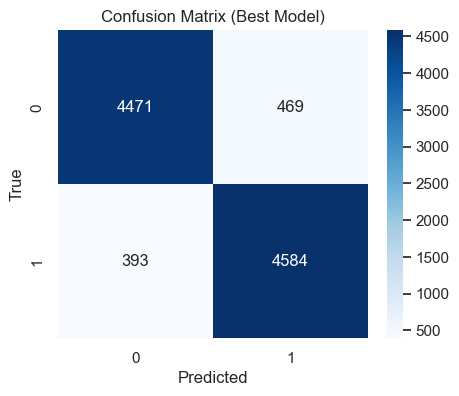

In [16]:
cm = best_run["confusion_matrix"]
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (Best Model)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

### 8) Model comparison visualization

A comparison plot makes it easy to see which pipeline family performs best.

Expected result: TF‑IDF with n-grams + a linear classifier (LogReg or LinearSVC) is typically among the top performers for this dataset.

C:\Users\sondo\AppData\Local\Temp\ipykernel_41632\1458271076.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, y="label", x="accuracy", ax=axes[0], palette="viridis")
C:\Users\sondo\AppData\Local\Temp\ipykernel_41632\1458271076.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, y="label", x="f1", ax=axes[1], palette="magma")


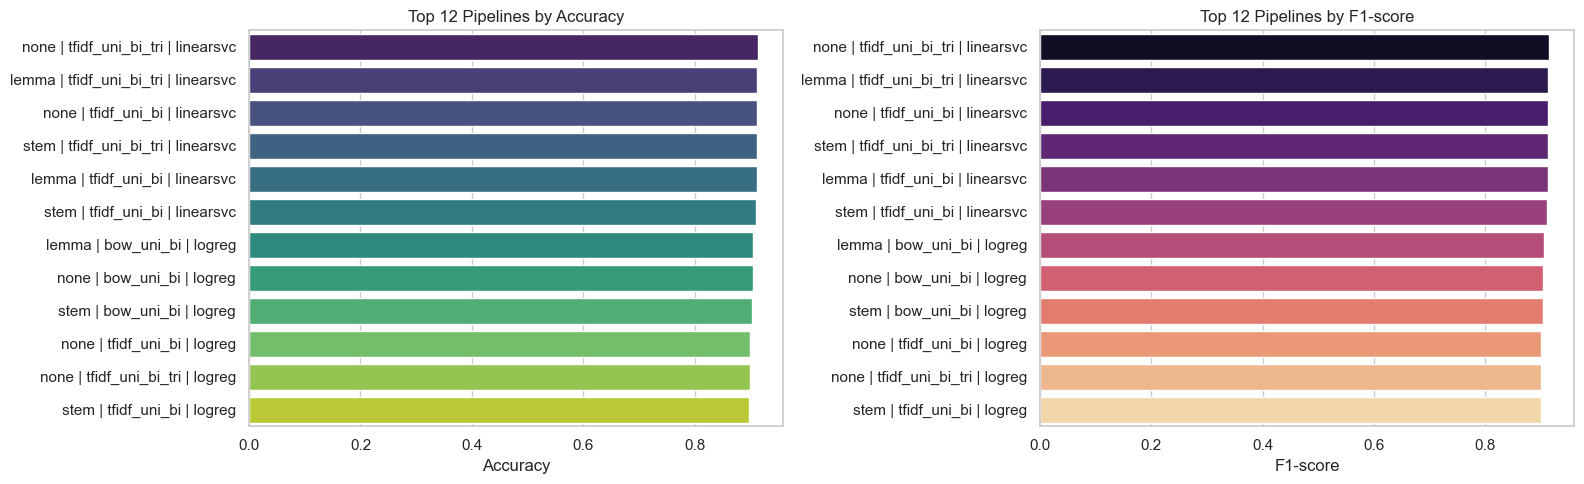

In [17]:
top_n = 12
plot_df = results_df.head(top_n).copy()
plot_df["label"] = (
    plot_df["preprocess"] + " | " + plot_df["features"] + " | " + plot_df["model"]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=plot_df, y="label", x="accuracy", ax=axes[0], palette="viridis")
axes[0].set_title(f"Top {top_n} Pipelines by Accuracy")
axes[0].set_xlabel("Accuracy")
axes[0].set_ylabel("")

sns.barplot(data=plot_df, y="label", x="f1", ax=axes[1], palette="magma")
axes[1].set_title(f"Top {top_n} Pipelines by F1-score")
axes[1].set_xlabel("F1-score")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

The figure compares the top-performing sentiment analysis pipelines using both accuracy and F1-score. The results show that TF-IDF feature extraction combined with LinearSVC consistently achieved the best performance, especially when using uni-grams, bi-grams, and tri-grams. The similarity between the accuracy and F1 rankings indicates balanced classification performance across classes.

### 9) Optional ROC curve (if best model supports decision scores)

ROC curves require a real-valued score (probability or decision function). Not all models expose probabilities.


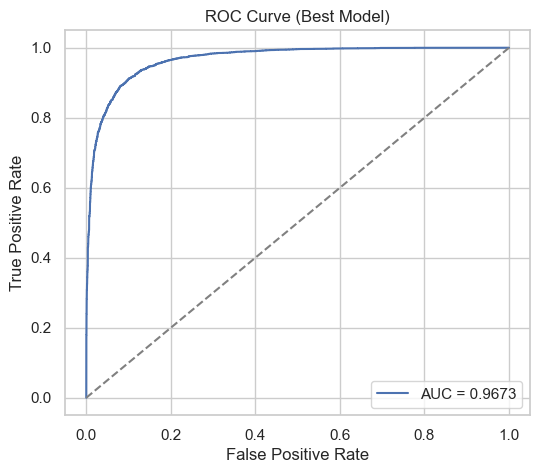

In [18]:
from sklearn.metrics import roc_curve, auc

def try_plot_roc(best_pipeline, prep_variant):
    X_test_p = preprocess_series(X_test, prep_variant)

    score = None
    if hasattr(best_pipeline.named_steps["clf"], "predict_proba"):
        score = best_pipeline.predict_proba(X_test_p)[:, 1]
    elif hasattr(best_pipeline.named_steps["clf"], "decision_function"):
        score = best_pipeline.decision_function(X_test_p)

    if score is None:
        print("Best model does not provide probability/decision scores. Skipping ROC.")
        return

    fpr, tpr, _ = roc_curve(y_test, score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
    plt.title("ROC Curve (Best Model)")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.show()

# Use the pipeline keyed by best_key so preprocessing matches the fitted vectorizer
try_plot_roc(pipeline_by_key[best_key], best_run["preprocess"])


Blue ROC curve: Your model’s actual performance.

Since the curve is very close to the top-left corner

that means: high true positive rate, low false positive rate which is excellent.

Most important metric:
AUC = 0.9673 (Area Under the Curve)

It summarizes overall classification quality (Excellent)

## Best Model Testing

In this section we **compare every traditional ML row** in `results_df` with the **deep learning** rows in `dl_results_df` (when TensorFlow ran successfully). The winner is the row with the **highest test accuracy**, using **F1-score as a tie-breaker** — the same idea as picking the best single number on a leaderboard.

We then run that **one best model** on a few **new short movie-review sentences** and print **Positive / Negative** plus the model **confidence** (probability of *positive* for neural nets; for classical models we use `predict_proba` when available, otherwise we fall back to `decision_function` scores scaled through a sigmoid for display only).


In [19]:
def pick_best_overall():
    ml_part = results_df.copy()
    ml_part["Category"] = "Traditional ML"
    if TENSORFLOW_AVAILABLE and len(dl_results_df) > 0:
        dl_part = dl_results_df.copy()
        dl_part["Category"] = "Deep Learning"
        comb = pd.concat([ml_part, dl_part], ignore_index=True)
    else:
        comb = ml_part.copy()
    comb = comb.sort_values(["accuracy", "f1"], ascending=False).reset_index(drop=True)
    return comb.iloc[0], comb

best_overall_row, combined_leaderboard = pick_best_overall()
print("Best overall (test accuracy, then F1):")
print(best_overall_row.to_string())
print()

custom_reviews = [
    "This movie was amazing and the acting was excellent.",
    "The film was boring, slow, and a waste of time.",
    "The story was okay but the ending was disappointing.",
    "I really enjoyed the characters and the soundtrack.",
]

def predict_custom_ml(row, texts):
    prep = row["preprocess"]
    feat = row["features"]
    mname = row["model"]
    run_key = f"prep={prep} | feat={feat} | model={mname}"
    pipe = pipeline_by_key.get(run_key)
    if pipe is None:
        return None
    s = pd.Series(texts)
    Xp = preprocess_series(s, prep)
    if hasattr(pipe.named_steps["clf"], "predict_proba"):
        p_pos = pipe.predict_proba(Xp)[:, 1]
    elif hasattr(pipe.named_steps["clf"], "decision_function"):
        s_raw = pipe.decision_function(Xp)
        p_pos = 1.0 / (1.0 + np.exp(-s_raw))
    else:
        p_pos = None
    yhat = pipe.predict(Xp)
    return yhat, p_pos

def predict_custom_dl(mname, texts):
    if not TENSORFLOW_AVAILABLE or mname not in dl_models_registry:
        return None
    model = dl_models_registry[mname]
    s = pd.Series(texts)
    Xp = preprocess_series(s, DL_PREP)
    Xpad = dl_texts_to_pad(Xp)
    proba = model.predict(Xpad, batch_size=64, verbose=0).ravel()
    yhat = (proba >= 0.5).astype(int)
    return yhat, proba

label_txt = {0: "Negative", 1: "Positive"}

cat = best_overall_row["Category"]
if cat == "Traditional ML":
    pr = predict_custom_ml(best_overall_row, custom_reviews)
    if pr is None:
        print("Could not load ML pipeline for best row; using top F1 pipeline from results_df.")
        pr = predict_custom_ml(
            results_df.sort_values(["f1", "accuracy"], ascending=False).iloc[0],
            custom_reviews,
        )
    yhat, ppos = pr
else:
    pr = predict_custom_dl(best_overall_row["model"], custom_reviews)
    yhat, ppos = pr if pr is not None else (None, None)

if yhat is not None:
    for txt, yi in zip(custom_reviews, yhat):
        print(f"Review: {txt}\n  -> {label_txt[int(yi)]}\n")
    if ppos is not None:
        print("Confidence (P(positive)):")
        for txt, yi, p in zip(custom_reviews, yhat, ppos):
            print(f"  {p:.4f}  |  {label_txt[int(yi)]}  |  {txt[:70]}")
else:
    print("No predictions to show.")


Best overall (test accuracy, then F1):
preprocess                none
features      tfidf_uni_bi_tri
model                linearsvc
accuracy              0.913079
precision             0.907184
recall                0.921037
f1                    0.914058
Category        Traditional ML

Review: This movie was amazing and the acting was excellent.
  -> Positive

Review: The film was boring, slow, and a waste of time.
  -> Negative

Review: The story was okay but the ending was disappointing.
  -> Negative

Review: I really enjoyed the characters and the soundtrack.
  -> Positive

Confidence (P(positive)):
  0.8197  |  Positive  |  This movie was amazing and the acting was excellent.
  0.0780  |  Negative  |  The film was boring, slow, and a waste of time.
  0.1857  |  Negative  |  The story was okay but the ending was disappointing.
  0.7894  |  Positive  |  I really enjoyed the characters and the soundtrack.


### 10) Final conclusions

We summarize the full project, including **traditional ML** pipelines and **deep learning** models:
- Best preprocessing choice among classical runs (none vs stem vs lemma)
- Best classical feature extraction (BoW vs TF‑IDF, and which n‑grams)
- Best classical model type
- Best **neural** model 
- **Best overall** model on the held-out test set.


In [ ]:
best_ml_row = results_df.sort_values(["f1", "accuracy"], ascending=False).iloc[0]

if TENSORFLOW_AVAILABLE and len(dl_results_df) > 0:
    best_dl_row = dl_results_df.sort_values(["accuracy", "f1"], ascending=False).iloc[0]
else:
    best_dl_row = None

ml_part = results_df.copy()
ml_part["Category"] = "Traditional ML"
if TENSORFLOW_AVAILABLE and len(dl_results_df) > 0:
    dl_part = dl_results_df.copy()
    dl_part["Category"] = "Deep Learning"
    combined_results_df = pd.concat([ml_part, dl_part], ignore_index=True)
else:
    combined_results_df = ml_part.copy()

combined_results_df = combined_results_df.sort_values(
    ["accuracy", "f1"], ascending=False
).reset_index(drop=True)
best_overall = combined_results_df.iloc[0]

summary = pd.DataFrame(
    {
        "Role": [
            "Best traditional ML (ranked by F1, then accuracy — same spirit as the main table)",
            "Best deep learning (ranked by test accuracy, then F1)",
            "Best overall (all models; test accuracy, then F1)",
        ],
        "Preprocessing": [
            best_ml_row["preprocess"],
            best_dl_row["preprocess"] if best_dl_row is not None else "—",
            best_overall["preprocess"],
        ],
        "Features / representation": [
            best_ml_row["features"],
            best_dl_row["features"] if best_dl_row is not None else "—",
            best_overall["features"],
        ],
        "Model": [
            best_ml_row["model"],
            best_dl_row["model"] if best_dl_row is not None else "—",
            best_overall["model"],
        ],
        "Category": [
            "Traditional ML",
            "Deep Learning" if best_dl_row is not None else "—",
            best_overall["Category"],
        ],
        "Accuracy": [
            best_ml_row["accuracy"],
            best_dl_row["accuracy"] if best_dl_row is not None else float("nan"),
            best_overall["accuracy"],
        ],
        "F1": [
            best_ml_row["f1"],
            best_dl_row["f1"] if best_dl_row is not None else float("nan"),
            best_overall["f1"],
        ],
    }
)

display(summary)

print(
    "\nWhy this worked best\n"
    "- Preprocessing removed HTML/noise and normalized tokens\n"
    "- Keeping negations preserved sentiment cues like 'not good'\n"
    "- TF-IDF and n-grams captured informative terms/phrases for classical models\n"
    "- Linear classifiers handle sparse high-dimensional text vectors well.\n"
    "- Deep models learned dense word embeddings and sequence structure (LSTM / BiLSTM) from token sequences\n"
)


,Role,Preprocessing,Features / representation,Model,Category,Accuracy,F1
0,"Best traditional ML (ranked by F1, then accura...",none,tfidf_uni_bi_tri,linearsvc,Traditional ML,0.913079,0.914058
1,"Best deep learning (ranked by test accuracy, t...",lemma,token_seq+embed+pad,dense_ann,Deep Learning,0.864173,0.865983
2,"Best overall (all models; test accuracy, then F1)",none,tfidf_uni_bi_tri,linearsvc,Traditional ML,0.913079,0.914058



Why this worked best (course connection):
- Preprocessing removed HTML/noise and normalized tokens (Lecture 2/3).
- Keeping negations preserved sentiment cues like 'not good' (Project2 idea).
- TF-IDF and n-grams captured informative terms/phrases for classical models (Lecture 6).
- Linear classifiers handle sparse high-dimensional text vectors well.
- Deep models learned dense word embeddings and sequence structure (LSTM / BiLSTM) from token sequences (labs / lectures on neural NLP).

